# The Law of Large Numbers and the Central Limit Theorem
### How random observations produce predictable averages

*An illustrated, executable tutorial based on a conversation about Bernoulli rewards, sample means, sampling distributions, and Gaussian limits.*

One of the most remarkable results in probability theory is that **averaging random observations produces predictable behavior**.

Suppose we repeatedly toss a biased coin. Each toss produces either `0` or `1`, with probability $p=0.6$ of obtaining `1`. A single toss is unpredictable, but the average of many tosses becomes increasingly reliable. Meanwhile, the distribution of those averages takes on an increasingly Gaussian *shape*.

Two questions drive this notebook:

1. **Law of Large Numbers (LLN):** Why does the average approach the true mean, $0.6$?
2. **Central Limit Theorem (CLT):** How can a distribution whose values are confined to $[0,1]$ become Gaussian-shaped, even though a Gaussian has support on the entire real line?

We'll distinguish **observations within an experiment** ($n$) from **repetitions of the entire experiment** ($K$), and use both exact probability calculations and simulations.

> **Run this notebook:** The figures are already included in the saved notebook. You can rerun the code cells or change $n$, $K$, or $p$ to experiment. Requires NumPy, SciPy, and Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

rng = np.random.default_rng(2026)
p = 0.6
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.18})

## 1. The original Bernoulli distribution

A Bernoulli random variable $X$ takes exactly two possible values:

$$P(X=1)=p,\qquad P(X=0)=1-p.$$

For $p=0.6$, the distribution has just two vertical bars, at 0 and 1. Its **population mean** and **population variance** are

$$\mu=\mathbb E[X]=p=0.6,\qquad \sigma^2=p(1-p)=0.24.$$

Therefore $\sigma=\sqrt{0.24}\approx0.490$. The mean need not be a possible individual observation: $0.6$ is not a Bernoulli reward.

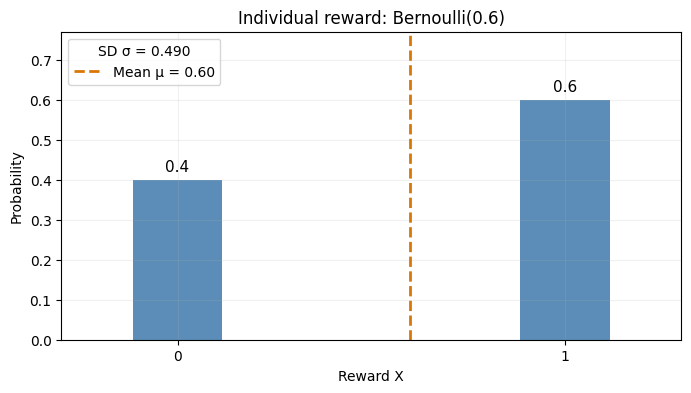

In [2]:
mu = p
sigma = np.sqrt(p * (1 - p))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([0, 1], [1-p, p], width=0.23, color=['#5B8DB8', '#5B8DB8'])
ax.axvline(mu, color='#D97706', linestyle='--', linewidth=2, label=f'Mean μ = {mu:.2f}')
for x, prob in [(0, 1-p), (1, p)]:
    ax.text(x, prob + 0.02, f'{prob:.1f}', ha='center', fontsize=11)
ax.set(xlim=(-0.3, 1.3), ylim=(0, 0.77), xticks=[0, 1], xlabel='Reward X', ylabel='Probability', title='Individual reward: Bernoulli(0.6)')
ax.legend(title=f'SD σ = {sigma:.3f}')
plt.show()

## 2. From Bernoulli to binomial

Suppose we make $n$ independent observations $X_1,\dots,X_n$, each distributed as $\mathrm{Bernoulli}(p)$. Their sum counts the number of successes:

$$S_n=\sum_{i=1}^n X_i\sim\operatorname{Binomial}(n,p).$$

In particular, $\mathbb E[S_n]=np$ and $\operatorname{Var}(S_n)=np(1-p)$.

For $n=25$, the sum can be any integer from 0 to 25—**26 possible values**. The mode is at 15 successes for $p=0.6$.

But we're interested in the **average**:

$$\bar X_n=\frac{S_n}{n}=\frac{1}{n}\sum_{i=1}^n X_i.$$

Its possible values are $0,1/n,2/n,\ldots,1$. There are still $n+1$ of them, but now they are spaced by $1/n$ rather than 1. The number of possible Bernoulli *sequences* is $2^n$; many different sequences have the same mean.

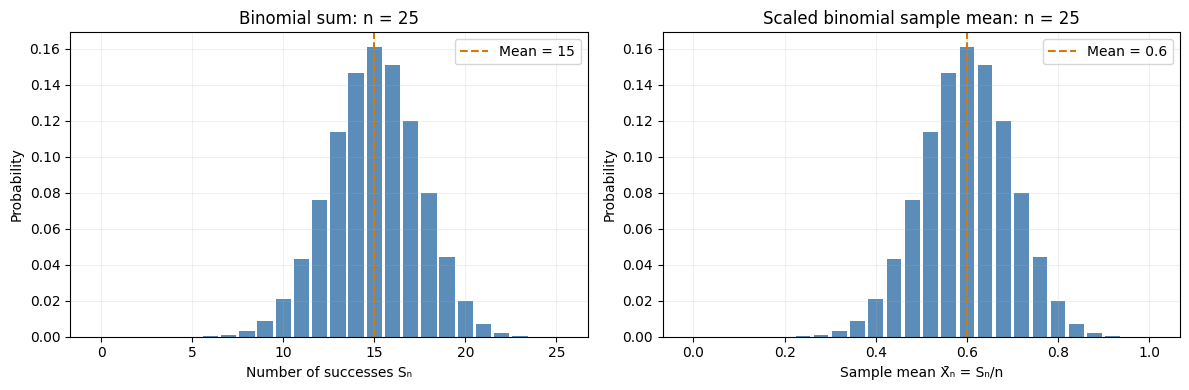

In [3]:
n = 25
k = np.arange(n + 1)
probs = binom.pmf(k, n, p)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(k, probs, width=0.85, color='#5B8DB8')
axes[0].axvline(n*p, color='#D97706', linestyle='--', label=f'Mean = {n*p:g}')
axes[0].set(xlabel='Number of successes Sₙ', ylabel='Probability', title='Binomial sum: n = 25')
axes[0].legend()
axes[1].bar(k/n, probs, width=0.032, color='#5B8DB8')
axes[1].axvline(p, color='#D97706', linestyle='--', label=f'Mean = {p:.1f}')
axes[1].set(xlabel='Sample mean X̄ₙ = Sₙ/n', ylabel='Probability', title='Scaled binomial sample mean: n = 25')
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. One experiment versus many experiments

There are **two independent counters** in our thought experiment:

- $n$ = the number of observations **within one experiment**.
- $K$ = the number of times we **repeat the entire experiment**.

One experiment with $n=25$ produces 25 individual zeros and ones, and **one sample mean**. Its raw-observation histogram has only two possible bars. A single mean, by itself, does not make a bell curve.

If we repeat the experiment $K$ times, we obtain $K$ sample means. A histogram of *those means* estimates the **sampling distribution of the sample mean**.

For any fixed $n$, that distribution is exactly a scaled binomial:

$$P\left(\bar X_n=\frac{k}{n}\right)=\binom nk p^k(1-p)^{n-k},\quad k=0,1,\ldots,n.$$

Crucially, **increasing $K$ reveals the fixed-$n$ distribution more accurately; it does not change that distribution or make it inherently more Gaussian**.

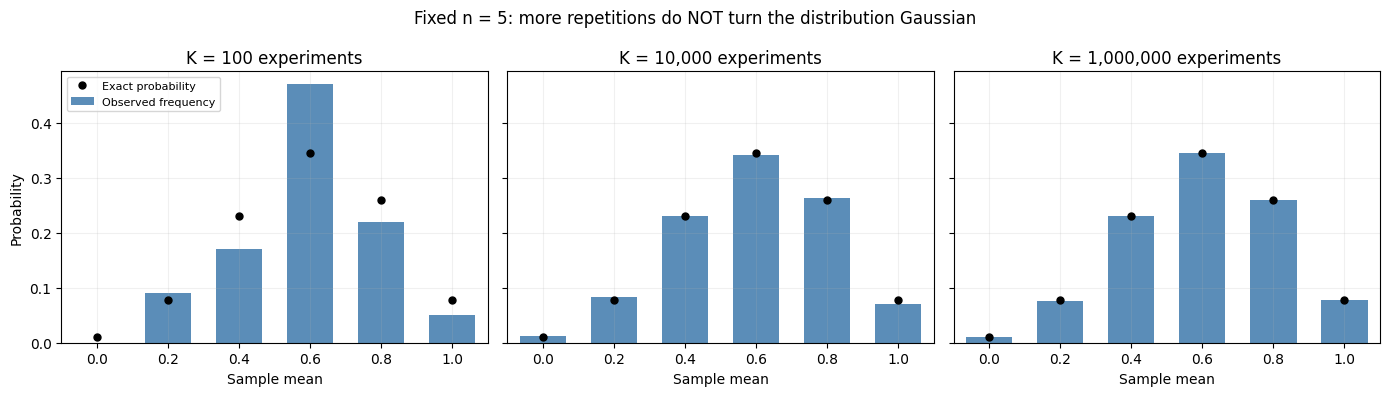

In [4]:
n = 5  # deliberately small to show that the sampling distribution stays discrete
repetitions = [100, 10_000, 1_000_000]
k = np.arange(n+1)
x = k/n
exact = binom.pmf(k, n, p)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, K in zip(axes, repetitions):
    counts = rng.binomial(n, p, size=K)
    empirical = np.bincount(counts, minlength=n+1)/K
    ax.bar(x, empirical, width=.13, color='#5B8DB8', label='Observed frequency')
    ax.plot(x, exact, 'ko', markersize=5, label='Exact probability')
    ax.set(xlim=(-.1,1.1), xticks=x, xlabel='Sample mean', title=f'K = {K:,} experiments')
axes[0].set_ylabel('Probability')
axes[0].legend(fontsize=8)
fig.suptitle('Fixed n = 5: more repetitions do NOT turn the distribution Gaussian')
plt.tight_layout()
plt.show()

## 4. Now increase $n$: more possible means, less spread

Hold the success probability at $p=0.6$ and examine the **exact** sampling distributions at $n=5,25,100,1000$.

As $n$ increases, two things happen:

1. The support has **$n+1$ points**, with spacing $1/n$, so it becomes more finely spaced across $[0,1]$.
2. The probability mass becomes more concentrated near the true mean $0.6$.

These aren't contradictory. The *set of possible outcomes* grows denser, even as the *probability of observing outcomes far from the true mean* becomes smaller.

To avoid confusion, we plot the sample mean on the horizontal axis—not the sum.

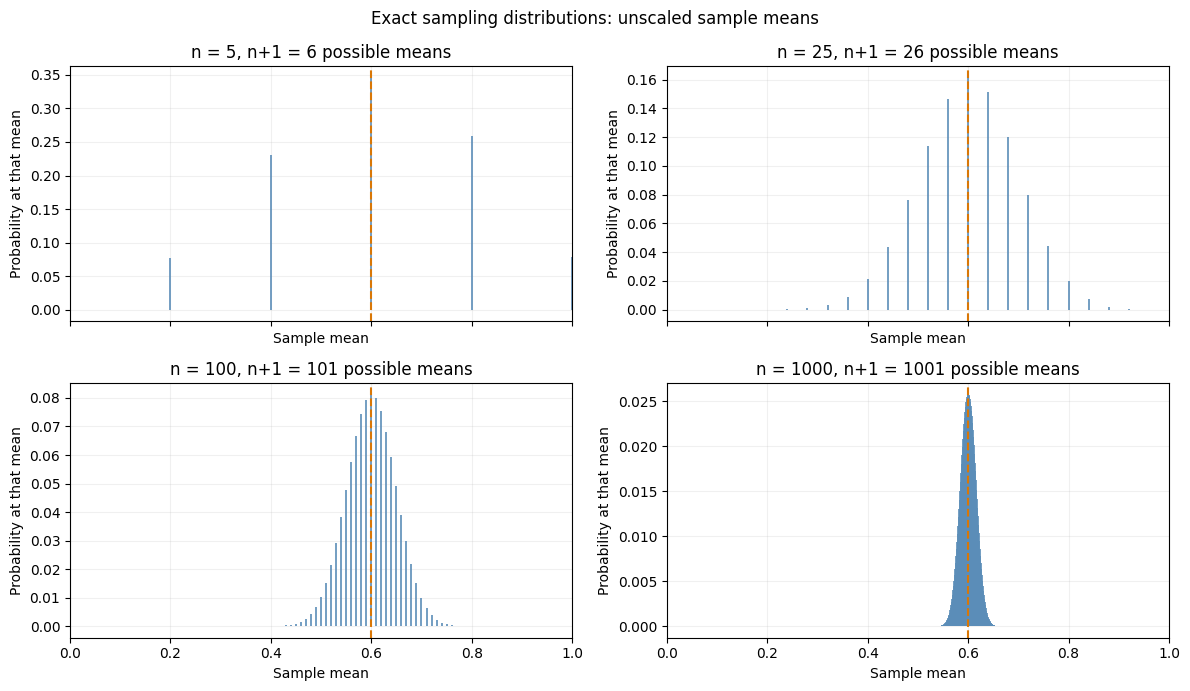

In [5]:
ns = [5, 25, 100, 1000]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, n in zip(axes.flat, ns):
    k = np.arange(n + 1)
    x = k/n
    probabilities = binom.pmf(k, n, p)
    ax.vlines(x, 0, probabilities, color='#5B8DB8', linewidth=1.2)
    ax.axvline(p, linestyle='--', color='#D97706', linewidth=1.5)
    ax.set(xlim=(0,1), title=f'n = {n}, n+1 = {n+1} possible means', xlabel='Sample mean', ylabel='Probability at that mean')
fig.suptitle('Exact sampling distributions: unscaled sample means')
plt.tight_layout()
plt.show()

## 5. The Law of Large Numbers

The **(weak) Law of Large Numbers** states that for independent, identically distributed observations with a finite expectation $\mu$,

$$\boxed{\bar X_n\xrightarrow{P}\mu.}$$

That is, for every fixed $\epsilon>0$,

$$\lim_{n\to\infty}P(|\bar X_n-\mu|>\epsilon)=0.$$

In our example, $\bar X_n\xrightarrow{P}0.6$. Equivalently, the distribution of $\bar X_n$ converges to a **point mass** at $0.6$.

Why does the spread shrink? Independence makes variances add:

$$\operatorname{Var}\left(\sum_{i=1}^n X_i\right)=n\sigma^2.$$

Because $\bar X_n=(\sum_iX_i)/n$, scaling by $1/n$ multiplies the variance by $1/n^2$:

$$\boxed{\operatorname{Var}(\bar X_n)=\frac{\sigma^2}{n},\qquad \operatorname{SD}(\bar X_n)=\frac{\sigma}{\sqrt n}.}$$

The standard deviation of the sample mean is the **standard error**. For our Bernoulli example, it is $\sqrt{0.24/n}$.

The law of large numbers describes where the sample mean goes. The next theorem describes the shape of the shrinking fluctuations.

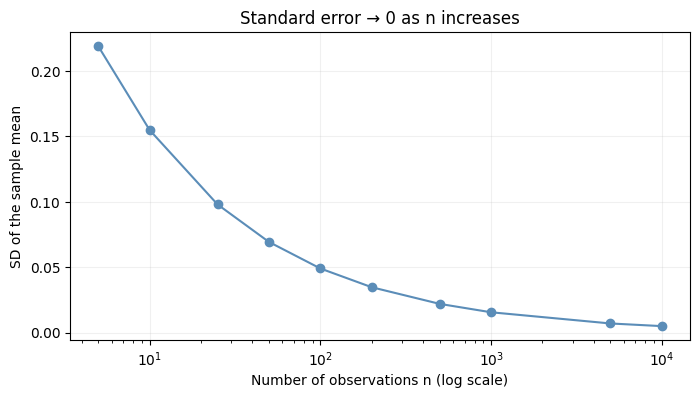

n    standard error
5    0.21909
25   0.09798
100  0.04899
1000 0.01549
100000.00490


In [6]:
ns = np.array([5, 10, 25, 50, 100, 200, 500, 1000, 5000, 10000])
se = np.sqrt(p*(1-p)/ns)
fig, ax = plt.subplots()
ax.plot(ns, se, marker='o', color='#5B8DB8')
ax.set_xscale('log')
ax.set(xlabel='Number of observations n (log scale)', ylabel='SD of the sample mean', title='Standard error → 0 as n increases')
plt.show()
print('n    standard error')
for n, s in zip(ns[[0,2,4,7,9]],se[[0,2,4,7,9]]):
    print(f'{n:<5d}{s:.5f}')

## 6. The Central Limit Theorem

Assume $X_1,\ldots,X_n$ are independent, identically distributed with finite mean $\mu$ and finite, nonzero variance $\sigma^2$. The **Central Limit Theorem** states:

$$\boxed{Z_n=\frac{\sqrt n(\bar X_n-\mu)}{\sigma}\xrightarrow{d}\mathcal N(0,1).}$$

The numerator subtracts the true mean; the denominator is the standard error. This *standardization* keeps the shrinking fluctuations on a common scale.

A convenient large-$n$ approximation for the **unstandardized** sample mean is

$$\bar X_n\approx\mathcal N\left(\mu,\frac{\sigma^2}{n}\right).$$

This does **not** mean the finite-$n$ distribution is exactly Gaussian. For Bernoulli rewards it is always discrete. Nor does it mean the unscaled sample mean converges to a non-degenerate Gaussian as $n\to\infty$: its distribution converges to a point mass at $\mu$.

Below we plot the exact Bernoulli distributions on a **standardized horizontal axis**, using density-scaled probability bars so that the standard normal density can be overlaid.

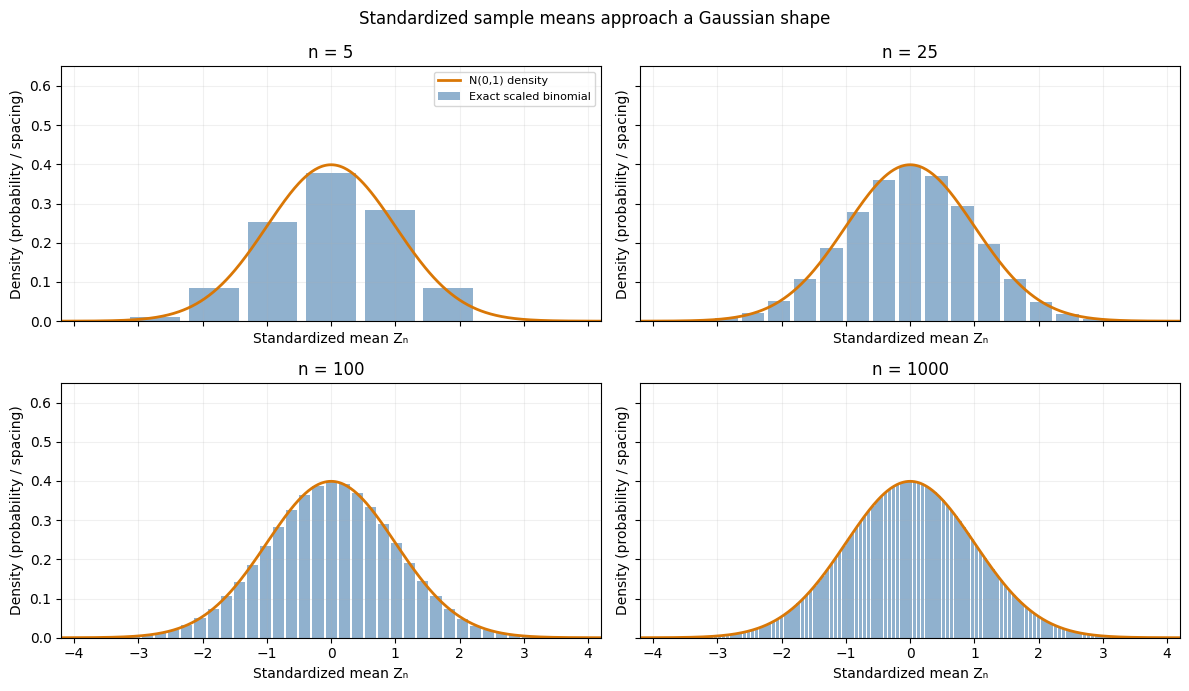

In [7]:
ns = [5, 25, 100, 1000]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
zgrid = np.linspace(-4.2, 4.2, 501)
for ax, n in zip(axes.flat, ns):
    k = np.arange(n+1)
    z = (k/n - p) / np.sqrt(p*(1-p)/n)
    probability = binom.pmf(k, n, p)
    dz = 1 / np.sqrt(n*p*(1-p))
    ax.bar(z, probability/dz, width=dz*.85, alpha=.68, color='#5B8DB8', label='Exact scaled binomial')
    ax.plot(zgrid, norm.pdf(zgrid), color='#D97706', linewidth=2, label='N(0,1) density')
    ax.set(xlim=(-4.2,4.2), ylim=(0,.65), xlabel='Standardized mean Zₙ', ylabel='Density (probability / spacing)', title=f'n = {n}')
axes[0,0].legend(fontsize=8)
fig.suptitle('Standardized sample means approach a Gaussian shape')
plt.tight_layout()
plt.show()

## 7. The bounded-support objection

A natural objection is: **How can an average that always stays in $[0,1]$ converge to a Gaussian, which has support on the whole real line?**

The answer is that the CLT concerns the standardized mean $Z_n$, not the unscaled $\bar X_n$. For Bernoulli rewards with $p=0.6$,

$$Z_n=\frac{\sqrt n(\bar X_n-0.6)}{\sqrt{0.24}}.$$

Because $0\le\bar X_n\le1$, we have

$$\boxed{-\sqrt{1.5n}\le Z_n\le\sqrt{\frac{2n}{3}}.}$$

Each finite-$n$ distribution is bounded, but **the bounds themselves expand toward $-\infty$ and $+\infty$ as $n$ increases**.

Further, convergence in distribution does not require two random variables to have identical support. For every fixed $n$, $Z_n$ is still discrete, but its cumulative distribution approaches the standard Gaussian cumulative distribution. That's a mathematically meaningful notion of convergence even though the discrete distribution never becomes exactly Gaussian at finite $n$.

This resolves the apparent paradox:

- Without standardization, $\bar X_n$ concentrates at $0.6$ (**LLN**).
- After standardization, $Z_n$ approaches $\mathcal N(0,1)$ (**CLT**).

The bell shape develops while the *original* bell simultaneously narrows.

In [8]:
ns = np.array([5, 25, 100, 1000, 10000])
low = -np.sqrt(1.5*ns)
high = np.sqrt(2*ns/3)
print(' n       min Zₙ       max Zₙ')
for n, a, b in zip(ns, low, high):
    print(f'{n:5d}   {a:10.2f}    {b:10.2f}')

 n       min Zₙ       max Zₙ
    5        -2.74          1.83
   25        -6.12          4.08
  100       -12.25          8.16
 1000       -38.73         25.82
10000      -122.47         81.65


## 8. Applications: confidence intervals and RL experiments

The CLT is useful because it quantifies how much the sample mean varies. If $\sigma$ is the population standard deviation, then

$$\operatorname{SE}(\bar X_n)=\frac{\sigma}{\sqrt n}.$$

When $\sigma$ is unknown we typically estimate it using the sample standard deviation $s$. For sufficiently large independent samples, an approximate 95% confidence interval for the true mean is

$$\boxed{\bar X_n\pm1.96\frac{s}{\sqrt n}.}$$

If, for example, $\bar X_n=5$, $s=2$, and $n=100$, then

$$\widehat{\operatorname{SE}}=0.2,\qquad \text{CI}\approx[4.608,5.392].$$

The **95%** refers to repeated-sampling *coverage*: if we repeated the data collection and interval construction, approximately 95% of the resulting intervals would contain the fixed true mean. It is not a statement that the fixed mean has a 95% frequentist probability of lying inside the particular interval we've already calculated.

For reinforcement learning, this matters whenever we average results over independently generated runs or problem instances. For example, if we compare epsilon-greedy and UCB, the CLT can help us estimate uncertainty in their mean rewards or cumulative regrets. If two algorithms are evaluated on the *same* random problem instances, it's often preferable to calculate **paired differences per instance** and estimate the standard error of the difference directly.

The CLT also motivates uncertainty estimates for independent Monte Carlo returns $G_i$ from a fixed state and policy:

$$\hat V_n^\pi(s)=\frac1n\sum_{i=1}^n G_i.$$

With suitable conditions, its error is approximately Gaussian on the standard-error scale. Correlated trajectories, nonstationarity, and biased estimators require additional care; the iid CLT cannot simply be applied without checking assumptions.

A caution: variance shrinking to zero doesn't eliminate **bias**. If your estimator converges to the wrong value, collecting more data merely makes you more precisely wrong.

## 9. Sampling distribution versus Bayesian posterior

A final distinction from Bayesian bandits:

- **Frequentist sampling distribution:** Treat $\mu$ as fixed and imagine many samples; $\bar X_n$ fluctuates around $\mu$.
- **Bayesian posterior:** Condition on an observed dataset $D$ and assign probabilities to candidate values of the unknown parameter: $p(\mu\mid D)$.

The CLT describes the first distribution. It doesn't require the second to be Gaussian. In a Bernoulli bandit, for instance, a Beta prior and Bernoulli likelihood yield a Beta posterior for the unknown success probability. Under additional regularity conditions, Bayesian posteriors often become approximately Gaussian at large sample sizes—related to the **Bernstein–von Mises theorem**—but that's a separate result.

## Conclusion

Starting with observations that can only be 0 or 1, we saw that their *sum* is binomial and their *mean* is a scaled binomial with $n+1$ possible values. Increasing the number of repetitions $K$ helps us see the sampling distribution; increasing the observations per experiment $n$ changes the sampling distribution itself.

The **Law of Large Numbers** says the unscaled mean converges to the true expected value. The **Central Limit Theorem** says the properly standardized fluctuations converge to a Gaussian. Both describe the same averaging process, from two complementary perspectives.

> **Takeaway:** More data makes the estimate concentrate around the truth, while the shape of its shrinking fluctuations becomes approximately Gaussian. The first is LLN; the second is CLT.